# Modelo de regresión del precio por noche

## Pregunta de negocio

¿Qué características observables de un alojamiento se asocian con su precio por noche y cuánto mejora un modelo de regresión frente a predecir la mediana?

Se ajusta un Random Forest con variables de capacidad, tipo de alojamiento, localidad, disponibilidad, reseñas y servicios. Los datos se leen de la base SQLite generada por el ETL, no de archivos CSV. El modelo es predictivo: sus asociaciones no demuestran causalidad y describen únicamente la instantánea analizada.

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

project_root = Path.cwd()
if not (project_root / "output" / "airbnb.sqlite").exists():
    project_root = project_root.parent
database_path = project_root / "output" / "airbnb.sqlite"
if not database_path.is_file():
    raise FileNotFoundError(
        f"No existe {database_path}. Ejecuta primero el ETL desde la raíz del proyecto."
    )

numeric_features = [
    "accommodates", "bedrooms", "bathrooms", "beds", "availability_365",
    "number_of_reviews", "reviews_per_month", "review_scores_rating",
    "amenities_count", "host_is_superhost",
]
categorical_features = ["room_type", "property_type", "neighbourhood_cleansed"]
target = "price"
selected_columns = numeric_features + categorical_features + [target]

with sqlite3.connect(database_path) as connection:
    available_columns = {
        row[1] for row in connection.execute('PRAGMA table_info("listings")')
    }
    missing_columns = set(selected_columns) - available_columns
    if missing_columns:
        raise ValueError(f"Faltan columnas requeridas en listings: {sorted(missing_columns)}")
    columns_sql = ", ".join(f'"{name}"' for name in selected_columns)
    listings = pd.read_sql_query(
        f"SELECT {columns_sql} FROM listings", connection
    )

print(f"Base: {database_path}")
print(f"Anuncios leídos: {len(listings):,}")
display(listings.head())

Base: C:\Users\Robin Montoya\OneDrive - INSTITUTO TECNOLOGICO METROPOLITANO - ITM\Documents\TallerETL2\TallerETL\output\airbnb.sqlite
Anuncios leídos: 19,187


,accommodates,bedrooms,bathrooms,beds,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,amenities_count,host_is_superhost,room_type,property_type,neighbourhood_cleansed,price
0,4.0,2.0,NaN,3.0,82.0,45.0,0.24,4.87,51,1,Entire home/apt,Entire serviced apartment,Chapinero,284294.01
1,3.0,1.0,1.0,1.0,236.0,33.0,0.19,4.75,33,1,Entire home/apt,Entire loft,Candelaria,215000.00
2,4.0,2.0,1.0,2.0,303.0,22.0,0.14,4.43,16,0,Entire home/apt,Entire rental unit,Chapinero,99196.10
3,4.0,3.0,2.0,3.0,353.0,3.0,0.03,5.00,31,0,Entire home/apt,Entire rental unit,Usaquen,179910.67
4,2.0,1.0,1.0,1.0,222.0,2.0,0.01,4.50,31,1,Private room,Private room in home,Teusaquillo,82260.75


## Preparación de datos

Se descartan precios nulos o no positivos y se recorta el conjunto de modelado a los percentiles 1–99 del precio. Es una decisión para limitar la influencia de registros extremos, no una afirmación de que sean errores: por eso se reportan el intervalo y los registros excluidos. La imputación y la codificación se ajustan dentro del pipeline usando solo los datos de entrenamiento, evitando filtrar información del conjunto de prueba.

In [2]:
for column in numeric_features + [target]:
    listings[column] = pd.to_numeric(listings[column], errors="coerce")

valid_prices = listings[target].dropna()
valid_prices = valid_prices[valid_prices > 0]
if len(valid_prices) < 20:
    raise ValueError("Se requieren al menos 20 anuncios con precio positivo para entrenar.")

lower_price, upper_price = valid_prices.quantile([0.01, 0.99])
model_data = listings.loc[
    listings[target].between(lower_price, upper_price, inclusive="both")
].copy()
excluded_count = len(listings) - len(model_data)

print(f"Intervalo de precio usado: ${lower_price:,.0f}–${upper_price:,.0f} COP por noche")
print(f"Anuncios incluidos: {len(model_data):,} de {len(listings):,}")
print(f"Anuncios excluidos por precio nulo, no positivo o fuera de percentiles: {excluded_count:,}")
display(model_data[target].describe(percentiles=[0.25, 0.5, 0.75]).to_frame("precio_COP"))

Intervalo de precio usado: $37,610–$1,330,087 COP por noche
Anuncios incluidos: 18,616 de 19,187
Anuncios excluidos por precio nulo, no positivo o fuera de percentiles: 571


,precio_COP
count,1.861600e+04
mean,1.967408e+05
std,1.489415e+05
min,3.761003e+04
25%,1.108741e+05
50%,1.614488e+05
75%,2.282360e+05
max,1.330000e+06


## Entrenamiento y evaluación

La partición aleatoria reserva el 20% de los anuncios para prueba. La línea base predice la mediana de los precios de entrenamiento. MAE y RMSE se expresan en COP por noche; R² mide la proporción de variación explicada en la muestra de prueba. Menor MAE/RMSE y mayor R² indican mejor desempeño, pero deben compararse con el alcance y las limitaciones de los datos.

In [3]:
X = model_data[numeric_features + categorical_features].copy()
y = model_data[target].astype(float)
for column in categorical_features:
    X[column] = X[column].astype("string")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )),
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)
baseline_predictions = np.full(len(y_test), y_train.median())

results = pd.DataFrame([
    {
        "Modelo": "Línea base: mediana",
        "MAE (COP)": mean_absolute_error(y_test, baseline_predictions),
        "RMSE (COP)": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        "R²": r2_score(y_test, baseline_predictions),
    },
    {
        "Modelo": "Random Forest",
        "MAE (COP)": mean_absolute_error(y_test, predictions),
        "RMSE (COP)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    },
])
display(results.style.format({"MAE (COP)": "${:,.0f}", "RMSE (COP)": "${:,.0f}", "R²": "{:.3f}"}))
mae_improvement = 1 - results.loc[1, "MAE (COP)"] / results.loc[0, "MAE (COP)"]
print(f"Reducción del MAE frente a la línea base: {mae_improvement:.1%}")

,Modelo,MAE (COP),RMSE (COP),R²
0,Línea base: mediana,"$87,432","$148,609",-0.053
1,Random Forest,"$60,590","$105,455",0.470


Reducción del MAE frente a la línea base: 30.7%


## Desempeño de las predicciones

La diagonal representa predicciones perfectas. La dispersión alrededor de ella muestra errores; el gráfico sirve para detectar si el modelo tiende a desviarse en rangos de precio particulares. Se muestran hasta 3.000 puntos para mantener legible la figura.

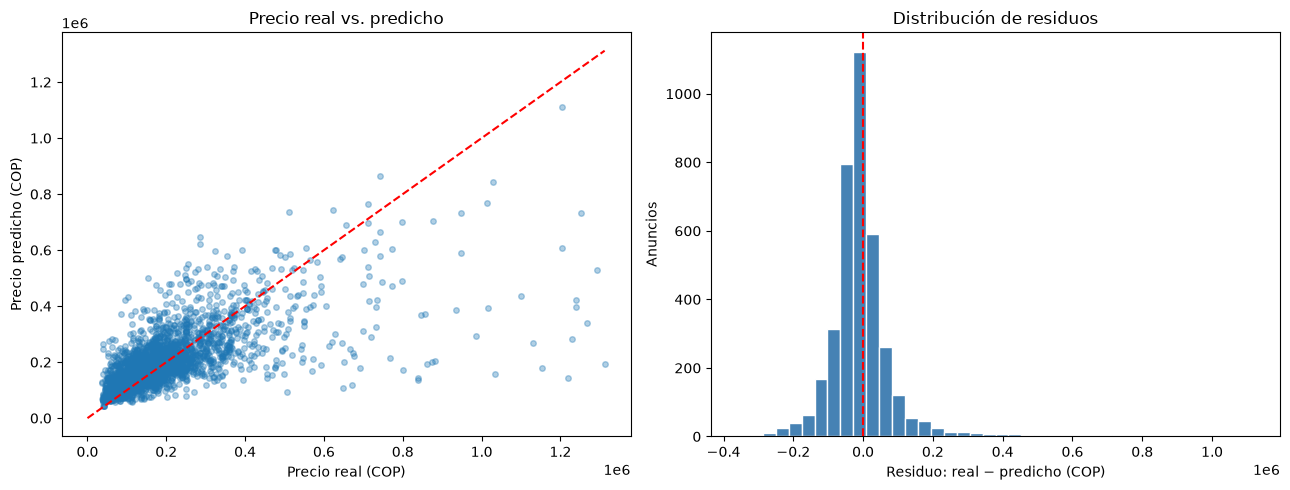

In [4]:
plot_size = min(3000, len(y_test))
plot_indices = np.random.default_rng(42).choice(len(y_test), size=plot_size, replace=False)
actual_sample = y_test.iloc[plot_indices]
predicted_sample = predictions[plot_indices]
axis_limit = max(actual_sample.max(), predicted_sample.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual_sample, predicted_sample, alpha=0.35, s=16)
axes[0].plot([0, axis_limit], [0, axis_limit], color="red", linestyle="--")
axes[0].set(xlabel="Precio real (COP)", ylabel="Precio predicho (COP)",
            title="Precio real vs. predicho")
axes[1].hist(y_test - predictions, bins=40, color="steelblue", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(xlabel="Residuo: real − predicho (COP)", ylabel="Anuncios",
            title="Distribución de residuos")
plt.tight_layout()
plt.show()

## Variables más importantes

La importancia por disminución de impureza resume cuánto contribuye cada variable al ajuste del bosque. Las variables categóricas se muestran por categoría codificada. Esta medida puede favorecer predictores con muchas categorías y no indica dirección ni causalidad; debe leerse junto con las métricas y el conocimiento del mercado.

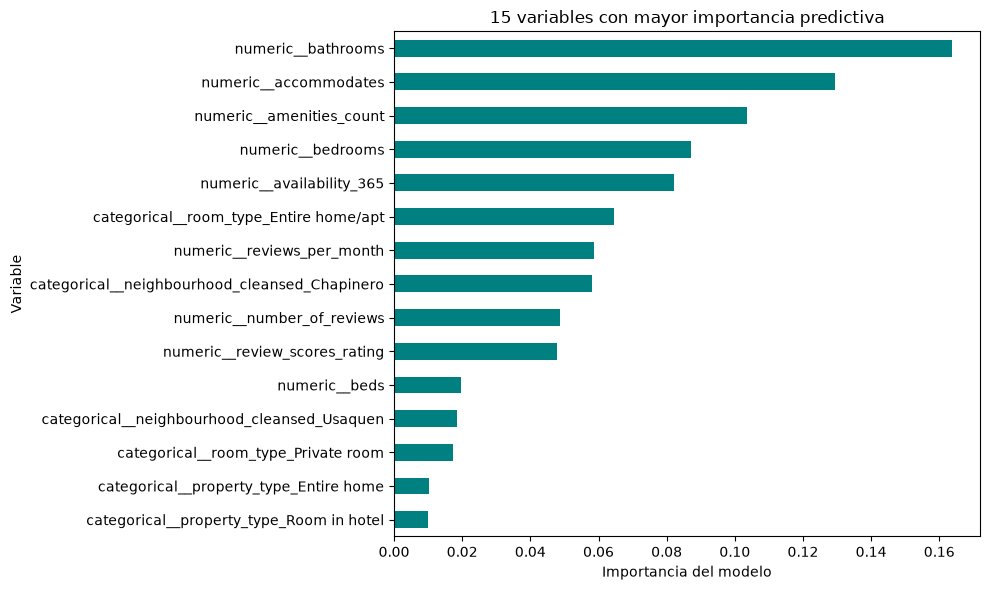

,importancia
numeric__bathrooms,0.163763
numeric__accommodates,0.129481
numeric__amenities_count,0.103686
numeric__bedrooms,0.087139
numeric__availability_365,0.082111
categorical__room_type_Entire home/apt,0.064525
numeric__reviews_per_month,0.058736
categorical__neighbourhood_cleansed_Chapinero,0.058070
numeric__number_of_reviews,0.048590
numeric__review_scores_rating,0.047915


In [5]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(
    model.named_steps["regressor"].feature_importances_, index=feature_names
).sort_values(ascending=False).head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
importance.plot.barh(ax=ax, color="teal")
ax.set(xlabel="Importancia del modelo", ylabel="Variable",
       title="15 variables con mayor importancia predictiva")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame("importancia"))

## Interpretación y límites

Antes de trasladar cifras al informe, verifica si el MAE es aceptable respecto a los precios observados y compáralo con la línea base. El precio publicado es una observación, no necesariamente el precio final reservado. Los resultados dependen del corte transversal, de la calidad y cobertura de campos, de la exclusión de extremos y de una división aleatoria; no prueban causalidad ni aseguran desempeño en datos futuros. La importancia no sustituye un análisis de efectos ni una validación temporal.

In [6]:
baseline_mae = results.loc[0, "MAE (COP)"]
model_mae = results.loc[1, "MAE (COP)"]
model_r2 = results.loc[1, "R²"]
if model_mae < baseline_mae:
    comparison = f"reduce el MAE un {1 - model_mae / baseline_mae:.1%} frente a la línea base"
else:
    comparison = f"no supera la línea base (MAE {model_mae:,.0f} frente a {baseline_mae:,.0f} COP)"

print(
    f"En la muestra de prueba (n={len(y_test):,}), el Random Forest {comparison}. "
    f"Su R² es {model_r2:.3f} y su MAE es {model_mae:,.0f} COP por noche. "
    "Presenta el resultado como asociación predictiva y explica las limitaciones antes de recomendar decisiones."
)

En la muestra de prueba (n=3,724), el Random Forest reduce el MAE un 30.7% frente a la línea base. Su R² es 0.470 y su MAE es 60,590 COP por noche. Presenta el resultado como asociación predictiva y explica las limitaciones antes de recomendar decisiones.
